In [2]:
import os

print("Current directory:", os.getcwd())
print("Project files:", os.listdir())

Current directory: d:\Datascience\projects\healthcare\project_1_chronic_kidney_disease\code_files
Project files: ['data_analyse.ipynb']


In [8]:
from pathlib import Path

dataset_folder = Path("../chronic_dataset")

for file_path in dataset_folder.glob("*.arff"):
    print(f"\n{'=' * 60}")
    print("FILE:", file_path.name)

    in_data = False

    with open(file_path, encoding="utf-8") as file:
        for line_number, line in enumerate(file, start=1):
            if line.strip().lower() == "@data":
                in_data = True
                print("\nDATA STARTS")
                continue

            if not in_data and line.strip().lower().startswith("@attribute"):
                print(line.strip())

            elif in_data and line.strip():
                print(f"\nFirst data row (line {line_number}):")
                print(repr(line))
                break


FILE: chronic_kidney_disease.arff
@attribute 'age' numeric
@attribute 'bp'  numeric
@attribute 'sg' {1.005,1.010,1.015,1.020,1.025}
@attribute 'al' {0,1,2,3,4,5}
@attribute 'su' {0,1,2,3,4,5}
@attribute 'rbc' {normal,abnormal}
@attribute 'pc' {normal,abnormal}
@attribute 'pcc' {present,notpresent}
@attribute 'ba' {present,notpresent}
@attribute 'bgr'  numeric
@attribute 'bu' numeric
@attribute 'sc' numeric
@attribute 'sod' numeric
@attribute 'pot' numeric
@attribute 'hemo' numeric
@attribute 'pcv' numeric
@attribute 'wbcc' numeric
@attribute 'rbcc' numeric
@attribute 'htn' {yes,no}
@attribute 'dm' {yes,no}
@attribute 'cad' {yes,no}
@attribute 'appet' {good,poor}
@attribute 'pe' {yes,no}
@attribute 'ane' {yes,no}
@attribute 'class' {ckd,notckd}

DATA STARTS

First data row (line 30):
'48,80,1.020,1,0,?,normal,notpresent,notpresent,121,36,1.2,?,?,15.4,44,7800,5.2,yes,yes,no,good,no,no,ckd\n'

FILE: chronic_kidney_disease_full.arff
@attribute 'age' numeric
@attribute 'bp'  numeric
@attri

In [9]:
from pathlib import Path

dataset_folder = Path("../chronic_dataset")

for file_path in dataset_folder.glob("*.arff"):
    if "_fixed" in file_path.name:
        continue

    print(f"\n{'=' * 60}")
    print("FILE:", file_path.name)

    in_data = False
    errors = []

    with open(file_path, encoding="utf-8") as file:
        for line_number, line in enumerate(file, start=1):

            if line.strip().lower() == "@data":
                in_data = True
                continue

            if not in_data or not line.strip() or line.strip().startswith("%"):
                continue

            values = [v.strip() for v in line.strip().split(",")]

            if len(values) != 25:
                errors.append((line_number, "Column count", len(values), values))

            elif values[21] not in ["good", "poor", "?"]:
                errors.append((line_number, "Invalid appet value", values[21], values))

    print("Problematic rows:", len(errors))

    for error in errors[:10]:
        print(error)


FILE: chronic_kidney_disease.arff
Problematic rows: 3
(99, 'Column count', 26, ['26', '70', '1.015', '0', '4', '?', 'normal', 'notpresent', 'notpresent', '250', '20', '1.1', '?', '?', '15.6', '52', '6900', '6.0', 'no', 'yes', 'no', 'good', 'no', 'no', 'ckd', ''])
(102, 'Column count', 26, ['64', '90', '1.010', '3', '3', '?', 'abnormal', 'present', 'notpresent', '?', '35', '1.3', '?', '?', '10.3', '?', '?', '?', 'yes', 'yes', 'no', 'good', 'yes', 'no', 'ckd', ''])
(399, 'Column count', 26, ['75', '70', '1.020', '0', '0', 'normal', 'normal', 'notpresent', 'notpresent', '107', '48', '0.8', '144', '3.5', '13.6', '46', '10300', '4.8', 'no', '', 'no', 'no', 'good', 'no', 'no', 'notckd'])

FILE: chronic_kidney_disease_full.arff
Problematic rows: 3
(215, 'Column count', 26, ['26', '70', '1.015', '0', '4', '?', 'normal', 'notpresent', 'notpresent', '250', '20', '1.1', '?', '?', '15.6', '52', '6900', '6.0', 'no', 'yes', 'no', 'good', 'no', 'no', 'ckd', ''])
(218, 'Column count', 26, ['64', '90'

In [10]:
from pathlib import Path

dataset_folder = Path("../chronic_dataset")

files = [
    "chronic_kidney_disease.arff",
    "chronic_kidney_disease_full.arff"
]

for filename in files:

    file_path = dataset_folder / filename
    lines = file_path.read_text(encoding="utf-8").splitlines()

    cleaned_lines = []
    in_data = False

    for line in lines:

        if line.strip().lower() == "@data":
            in_data = True
            cleaned_lines.append(line)
            continue

        if in_data and line.strip():

            values = [value.strip() for value in line.split(",")]

            # Remove extra trailing empty field
            if len(values) == 26 and values[-1] == "":
                values = values[:-1]

            # Correct the record with missing dm and shifted values
            if len(values) == 26 and values[18:26] == [
                "no", "", "no", "no", "good", "no", "no", "notckd"
            ]:
                values = values[:19] + [
                    "?", "no", "good", "no", "no", "notckd"
                ]

            cleaned_lines.append(",".join(values))

        else:
            cleaned_lines.append(line)

    fixed_path = dataset_folder / f"{file_path.stem}_corrected.arff"
    fixed_path.write_text("\n".join(cleaned_lines), encoding="utf-8")

    print("Corrected:", fixed_path.name)

print("\nCorrection completed!")

Corrected: chronic_kidney_disease_corrected.arff
Corrected: chronic_kidney_disease_full_corrected.arff

Correction completed!


In [11]:
from pathlib import Path

dataset_folder = Path("../chronic_dataset")

for file_path in dataset_folder.glob("*_corrected.arff"):

    in_data = False
    total_rows = 0
    invalid_rows = []

    with open(file_path, encoding="utf-8") as file:
        for line_number, line in enumerate(file, start=1):

            if line.strip().lower() == "@data":
                in_data = True
                continue

            if not in_data or not line.strip() or line.strip().startswith("%"):
                continue

            values = [value.strip() for value in line.split(",")]
            total_rows += 1

            if len(values) != 25:
                invalid_rows.append((line_number, "Column count", len(values)))

            elif values[21] not in ["good", "poor", "?"]:
                invalid_rows.append((line_number, "Invalid appetite", values[21]))

    print("\nFile:", file_path.name)
    print("Total records:", total_rows)
    print("Invalid rows:", len(invalid_rows))
    print("Validation:", "PASSED" if not invalid_rows else "FAILED")

    for error in invalid_rows:
        print(error)


File: chronic_kidney_disease_corrected.arff
Total records: 400
Invalid rows: 0
Validation: PASSED

File: chronic_kidney_disease_full_corrected.arff
Total records: 400
Invalid rows: 0
Validation: PASSED


In [12]:
from pathlib import Path
import pandas as pd
from scipy.io import arff

dataset_folder = Path("../chronic_dataset")

files = [
    "chronic_kidney_disease_corrected.arff",
    "chronic_kidney_disease_full_corrected.arff"
]

for filename in files:

    file_path = dataset_folder / filename

    data, metadata = arff.loadarff(file_path)

    df = pd.DataFrame(data)

    # Decode byte values
    for column in df.select_dtypes(include=["object"]).columns:
        df[column] = df[column].apply(
            lambda value: value.decode("utf-8") if isinstance(value, bytes) else value
        )

    # Replace missing-value markers
    df.replace("?", pd.NA, inplace=True)

    csv_path = dataset_folder / f"{file_path.stem}.csv"
    df.to_csv(csv_path, index=False)

    print("\nFile:", csv_path.name)
    print("Shape:", df.shape)
    print("Saved successfully:", csv_path.exists())

print("\nARFF to CSV conversion completed!")


File: chronic_kidney_disease_corrected.csv
Shape: (400, 25)
Saved successfully: True

File: chronic_kidney_disease_full_corrected.csv
Shape: (400, 25)
Saved successfully: True

ARFF to CSV conversion completed!


In [13]:
import pandas as pd
from pathlib import Path

dataset_folder = Path("../chronic_dataset")

file1 = dataset_folder / "chronic_kidney_disease_corrected.csv"
file2 = dataset_folder / "chronic_kidney_disease_full_corrected.csv"

df1 = pd.read_csv(file1)
df2 = pd.read_csv(file2)

print("FILE COMPARISON")
print("=" * 50)

print("File 1 Shape:", df1.shape)
print("File 2 Shape:", df2.shape)

print("\nColumn Names Identical:", list(df1.columns) == list(df2.columns))
print("Data Identical:", df1.equals(df2))

print("\nMissing Values:")
print("File 1:", df1.isnull().sum().sum())
print("File 2:", df2.isnull().sum().sum())

print("\nDuplicate Rows:")
print("File 1:", df1.duplicated().sum())
print("File 2:", df2.duplicated().sum())

print("\nClass Distribution - File 1:")
print(df1["class"].value_counts(dropna=False))

print("\nClass Distribution - File 2:")
print(df2["class"].value_counts(dropna=False))

print("\nDifferent Rows:", (df1 != df2).any(axis=1).sum())

FILE COMPARISON
File 1 Shape: (400, 25)
File 2 Shape: (400, 25)

Column Names Identical: True
Data Identical: True

Missing Values:
File 1: 1013
File 2: 1013

Duplicate Rows:
File 1: 0
File 2: 0

Class Distribution - File 1:
class
ckd       250
notckd    150
Name: count, dtype: int64

Class Distribution - File 2:
class
ckd       250
notckd    150
Name: count, dtype: int64

Different Rows: 243


## data analyses

In [3]:
import pandas as pd

In [5]:
data=pd.read_csv(r"D:\Datascience\projects\healthcare\project_1_chronic_kidney_disease\chronic_dataset\chronic_kidney_disease_full_corrected.csv")

In [7]:
data.shape

(400, 25)

In [8]:
data.columns

Index(['age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr', 'bu',
       'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc', 'htn', 'dm', 'cad',
       'appet', 'pe', 'ane', 'class'],
      dtype='str')

In [9]:
data.head()

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35.0,7300.0,4.6,no,no,no,good,no,no,ckd


In [10]:
data.isnull().sum()

age        9
bp        12
sg        47
al        46
su        49
rbc      152
pc        65
pcc        4
ba         4
bgr       44
bu        19
sc        17
sod       87
pot       88
hemo      52
pcv       71
wbcc     106
rbcc     131
htn        2
dm         3
cad        2
appet      1
pe         1
ane        1
class      0
dtype: int64

In [15]:
data.duplicated().sum()

np.int64(0)

In [17]:
data['class'].value_counts()

class
ckd       250
notckd    150
Name: count, dtype: int64

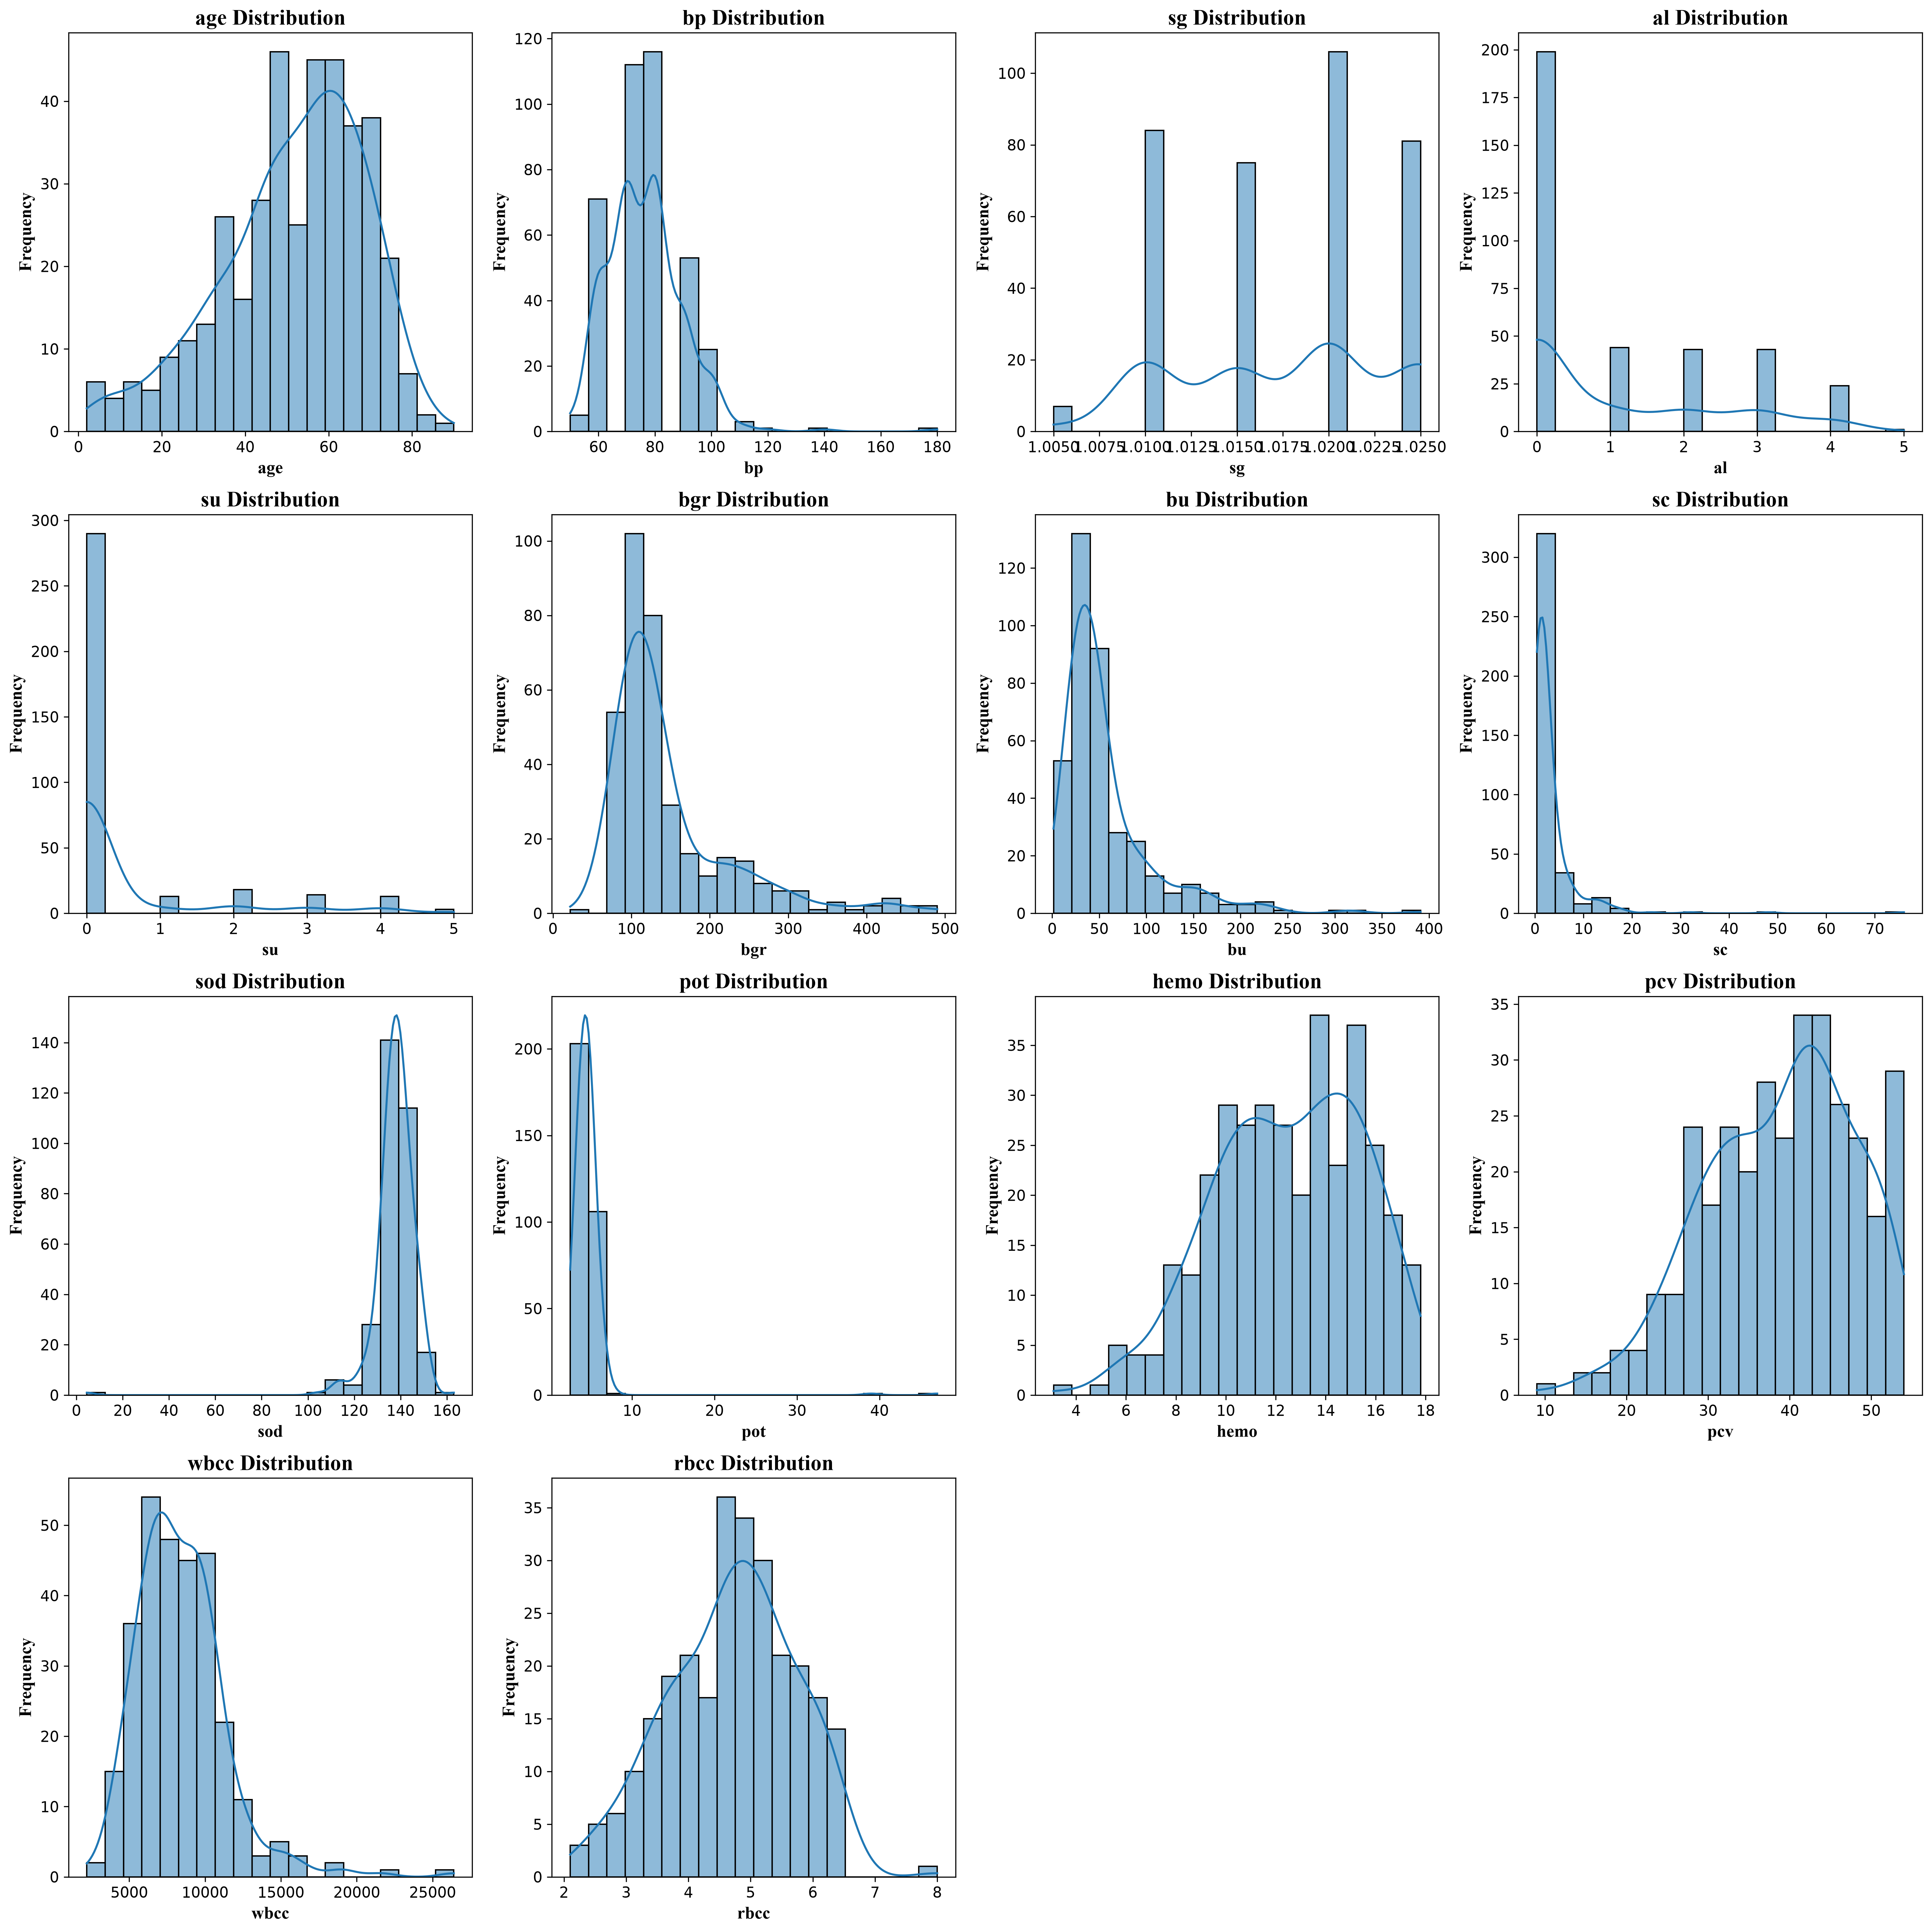

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Select numerical columns
numeric_data = data.drop(columns=["class"]).apply(
    pd.to_numeric, errors="coerce"
)

numerical_columns = [
    col for col in numeric_data.columns
    if numeric_data[col].notna().any()
]

# Subplot layout
n_cols = 4
n_rows = math.ceil(len(numerical_columns) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(20, 5 * n_rows),
    dpi=300
)

axes = np.array(axes).flatten()

# Plot distributions
for i, column in enumerate(numerical_columns):

    sns.histplot(
        numeric_data[column].dropna(),
        kde=True,
        bins=20,
        ax=axes[i]
    )

    axes[i].set_title(
        f"{column} Distribution",
        fontsize=16,
        fontweight="bold",
        fontname="Times New Roman"
    )

    axes[i].set_xlabel(
        column,
        fontsize=13,
        fontweight="bold",
        fontname="Times New Roman"
    )

    axes[i].set_ylabel(
        "Frequency",
        fontsize=13,
        fontweight="bold",
        fontname="Times New Roman"
    )

    axes[i].tick_params(labelsize=11)

# Remove unused subplots
for j in range(len(numerical_columns), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [20]:
data.describe()

,age,bp,sg,al,su,bgr,bu,sc,sod,pot,hemo,pcv,wbcc,rbcc
count,391.000000,388.000000,353.000000,354.000000,351.000000,356.000000,381.000000,383.000000,313.000000,312.000000,348.000000,329.000000,294.000000,269.000000
mean,51.483376,76.469072,1.017408,1.016949,0.450142,148.036517,57.425722,3.072454,137.528754,4.627244,12.526437,38.884498,8406.122449,4.707435
std,17.169714,13.683637,0.005717,1.352679,1.099191,79.281714,50.503006,5.741126,10.408752,3.193904,2.912587,8.990105,2944.474190,1.025323
min,2.000000,50.000000,1.005000,0.000000,0.000000,22.000000,1.500000,0.400000,4.500000,2.500000,3.100000,9.000000,2200.000000,2.100000
25%,42.000000,70.000000,1.010000,0.000000,0.000000,99.000000,27.000000,0.900000,135.000000,3.800000,10.300000,32.000000,6500.000000,3.900000
50%,55.000000,80.000000,1.020000,0.000000,0.000000,121.000000,42.000000,1.300000,138.000000,4.400000,12.650000,40.000000,8000.000000,4.800000
75%,64.500000,80.000000,1.020000,2.000000,0.000000,163.000000,66.000000,2.800000,142.000000,4.900000,15.000000,45.000000,9800.000000,5.400000
max,90.000000,180.000000,1.025000,5.000000,5.000000,490.000000,391.000000,76.000000,163.000000,47.000000,17.800000,54.000000,26400.000000,8.000000


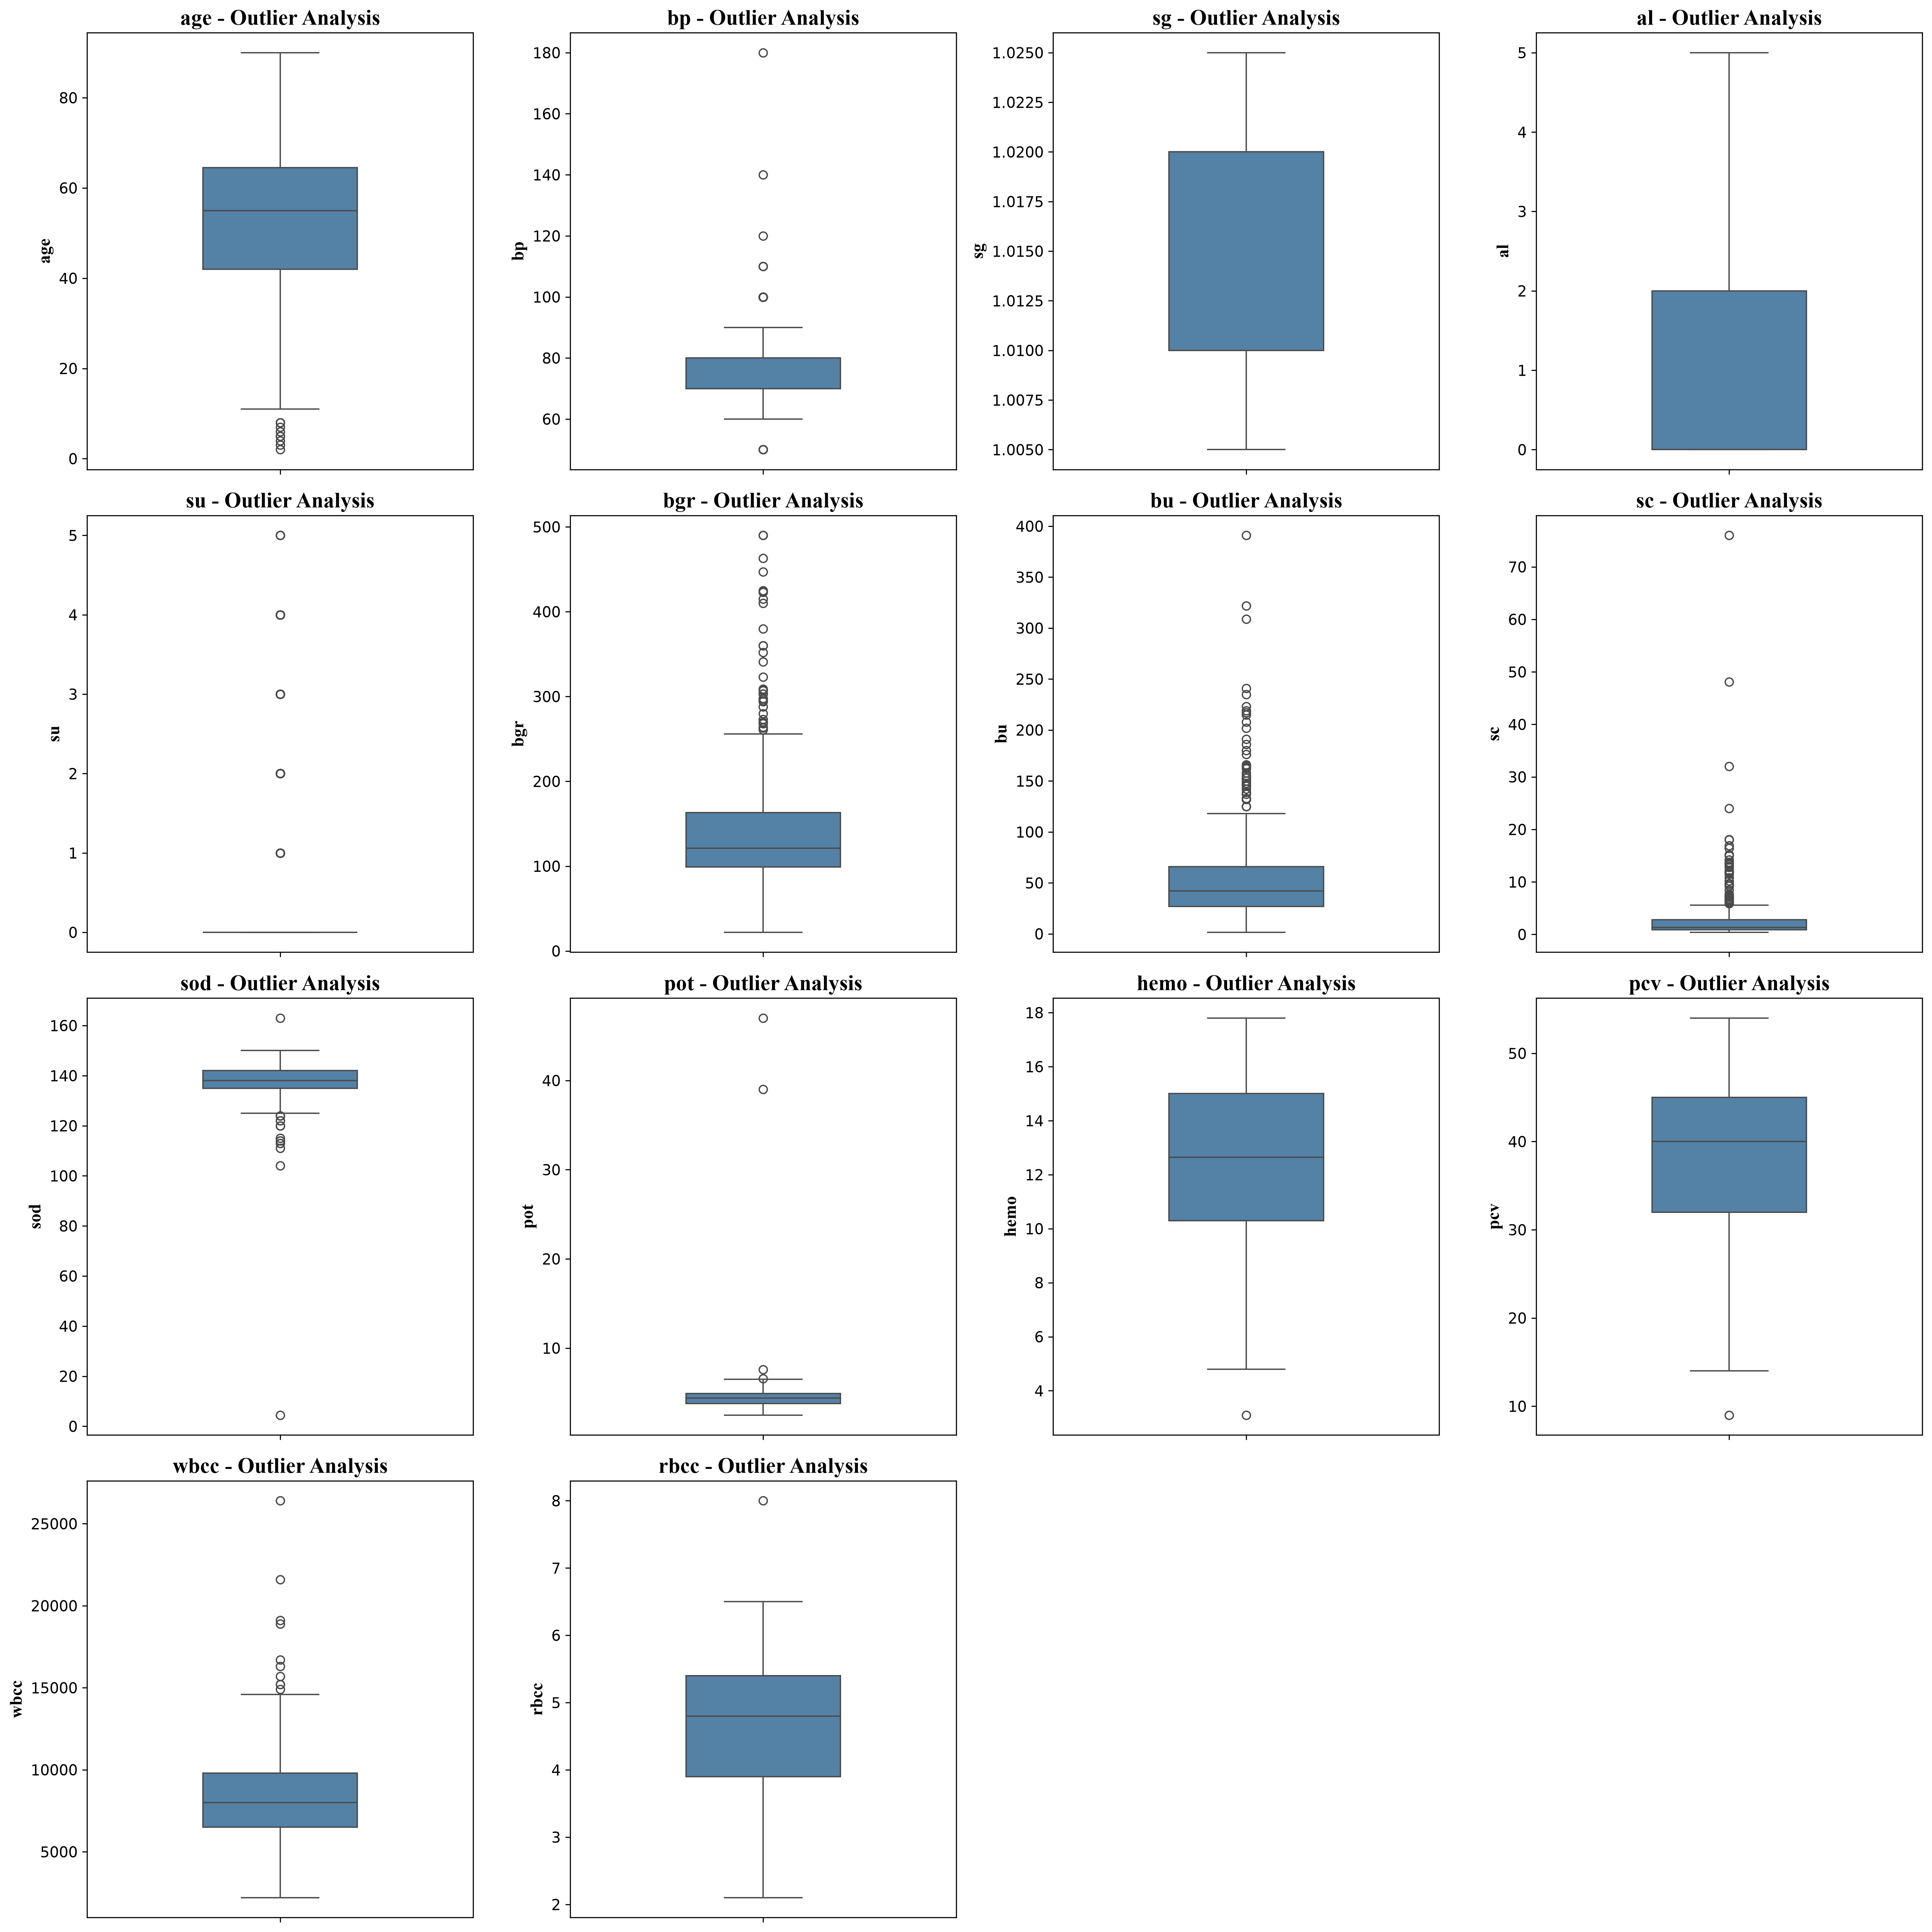

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Select numerical columns
numeric_data = data.drop(columns=["class"]).apply(
    pd.to_numeric, errors="coerce"
)

numerical_columns = numeric_data.columns[
    numeric_data.notna().any()
].tolist()

# Create subplot layout
n_cols = 4
n_rows = math.ceil(len(numerical_columns) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(20, 5 * n_rows),
    dpi=300
)

axes = np.array(axes).flatten()

# Plot boxplots
for i, column in enumerate(numerical_columns):

    sns.boxplot(
        y=numeric_data[column],
        ax=axes[i],
        color="steelblue",
        width=0.4
    )

    axes[i].set_title(
        f"{column} - Outlier Analysis",
        fontsize=16,
        fontweight="bold",
        fontname="Times New Roman"
    )

    axes[i].set_xlabel(
        "",
        fontname="Times New Roman"
    )

    axes[i].set_ylabel(
        column,
        fontsize=13,
        fontweight="bold",
        fontname="Times New Roman"
    )

    axes[i].tick_params(labelsize=11)

    axes[i].grid(False)

# Remove unused subplots
for j in range(len(numerical_columns), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [22]:
data.dtypes

age      float64
bp       float64
sg       float64
al       float64
su       float64
rbc          str
pc           str
pcc          str
ba           str
bgr      float64
bu       float64
sc       float64
sod      float64
pot      float64
hemo     float64
pcv      float64
wbcc     float64
rbcc     float64
htn          str
dm           str
cad          str
appet        str
pe           str
ane          str
class        str
dtype: object

In [23]:
# Missing value percentage for each column

missing_analysis = pd.DataFrame({
    "Missing_Count": data.isnull().sum(),
    "Missing_Percentage": (data.isnull().sum() / len(data)) * 100
})

missing_analysis = missing_analysis.sort_values(
    by="Missing_Percentage",
    ascending=False
)

print(missing_analysis.round(2))

       Missing_Count  Missing_Percentage
rbc              152               38.00
rbcc             131               32.75
wbcc             106               26.50
pot               88               22.00
sod               87               21.75
pcv               71               17.75
pc                65               16.25
hemo              52               13.00
su                49               12.25
sg                47               11.75
al                46               11.50
bgr               44               11.00
bu                19                4.75
sc                17                4.25
bp                12                3.00
age                9                2.25
pcc                4                1.00
ba                 4                1.00
dm                 3                0.75
htn                2                0.50
cad                2                0.50
appet              1                0.25
pe                 1                0.25
ane             

In [26]:
# Encode target column
data["class_encoded"] = data["class"].map({
    "notckd": 0,
    "ckd": 1
})

# Calculate correlation with target
target_correlation = (
    data.select_dtypes(include=["number"])
    .corr()["class_encoded"]
    .drop("class_encoded")
    .sort_values(ascending=False)
)

print("Correlation with CKD Target:\n")
print(target_correlation.round(4))

Correlation with CKD Target:

al      0.6271
bgr     0.4197
bu      0.3806
su      0.3441
sc      0.3000
bp      0.2941
wbcc    0.2319
age     0.2273
pot     0.0845
sod    -0.3757
rbcc   -0.6991
sg     -0.7322
pcv    -0.7414
hemo   -0.7689
Name: class_encoded, dtype: float64
